# TD 4: Bayesian inference with Metropolis sampling: From noisy measurements to Gravitational waves.

The aim is to apply the statistical tools from the course to a real dataset. First, we infer a slope and an intercept from artificial noisy measurements. Then, we reuse the same reasoning and sampler for the gravitational-wave event GW150914.

The physical model and data preparation in Part 2 are supplied. You do not need to derive the gravitational-wave model or understand every line of its preparation code. You need to understand what data it returns, which parameters the model uses, and how the noise enters the likelihood. We thank Eric Chassande-Mottin (laboratoire AstroParticule et Cosmologie (APC) Paris) for his help on accessing and treating the data on the first iterations of the course.

Across the two sessions we use $d$ for data, $\theta$ for parameters, $\mathcal L(d\mid\theta)$ for the likelihood, $\pi(\theta)$ for the prior, and $p(\theta\mid d)$ for the posterior. A chain is the sequence of parameter values generated by the sampler.


**Requirements:** NumPy, SciPy, Matplotlib, `corner`, PyCBC and LALSuite. If necessary, install them in a separate cell with `%pip install numpy scipy matplotlib corner pycbc lalsuite`, then restart the kernel. Keep the two `GW150914_*_raw.npz` files beside this notebook. They allow Part 2 to run without downloading data during class.



In [54]:
import numpy as np
from matplotlib import pyplot as plt
import corner
from pathlib import Path
from time import perf_counter

plt.rcParams.update({"figure.figsize": (8, 4), "font.size": 11,
                     "axes.grid": False, "grid.alpha": 0.25})

In [55]:
# %matplotlib widget
%matplotlib inline

## Part 1 — Artificial data

The model is a straight line:

$$
f(x_n,\theta)=a_1x_n+a_2,\qquad \theta=(a_1,a_2).
$$

We consider $M=200$ observations with $x_n=n/M$, $n=0,\ldots,M-1$, and true parameters $\theta^*=(30,800)$:

$$
d_n=f(x_n,\theta^*)+\epsilon_n,
\qquad \epsilon_n\sim\mathcal N(0,\sigma_n^2).
$$

The noises are independent, but their standard deviations differ: $\sigma_n=e^{\alpha_n}$ with $\alpha_n$ uniform on $[-2,6]$. This gives log-uniform noise scales. Once generated, the $\sigma_n$ are treated as known.

The aim of the first part of the tutorial will be to infer the parameters $a_1^*$ and $a_2^*$ from the measures of $d_n$ knowing the standard deviations $\sigma_n$. As we will see later, this model shares many similarities with the one we will be using for the second part: two parameters and different but fixed standard deviations.


### Q0. Generate and inspect the data

Generate and plot the data and noise scales.

In [56]:
rng = np.random.default_rng(42)

M = 200
a1_t = 30
a2_t = 800

x = np.arange(M) / M
alpha = rng.uniform(-2, 6, M)
sigma = np.exp(alpha)

true_signal = a1_t * x + a2_t
epsilon = rng.normal(0, sigma)
d = true_signal + epsilon


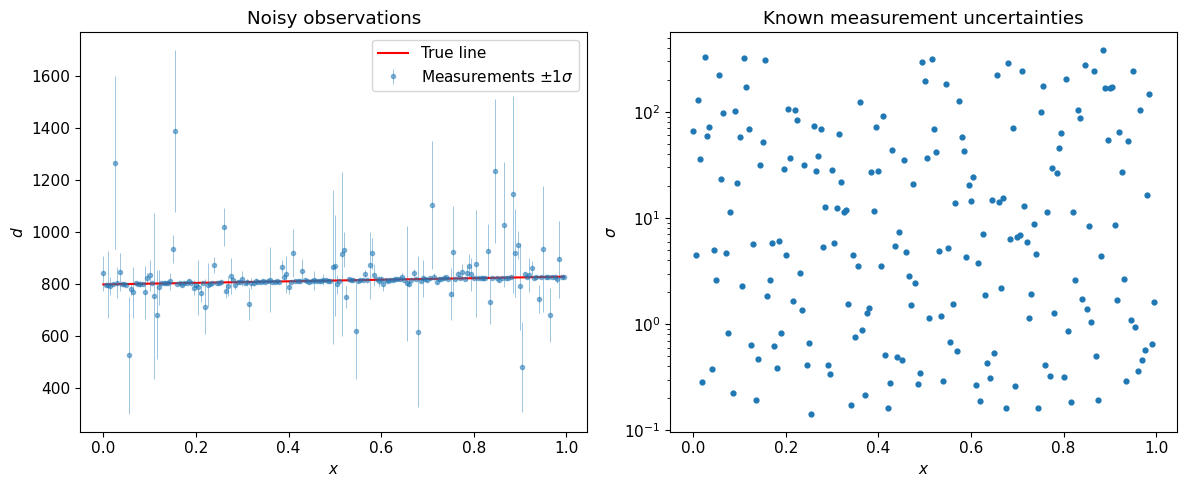

In [57]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax1, ax2 = ax

ax1.errorbar(x, d, yerr=sigma, fmt=".", alpha=0.5, lw=.6, label=r"Measurements $\pm 1\sigma$")
ax1.plot(x, true_signal, color="red", label="True line")
ax1.set(xlabel=r"$x$", ylabel=r"$d$", title="Noisy observations")
ax1.legend()

ax2.scatter(x, sigma, s=12)
ax2.set_yscale("log")
ax2.set(xlabel=r"$x$", ylabel=r"$\sigma$", title="Known measurement uncertainties")

plt.tight_layout()
plt.show()

### Q1. Log likelihood

Write the log-likelihood distribution of the signal $d=(d_n)_{n=1,\ldots, M}$ given the parameters $\theta$ of the model, the gaussian noise and the observations. What simplifying assumptions can you make?

Write a function returning the parameter-dependent part of the log-likelihood



The observations follow the model
$$
d_n = a_1x_n + a_2 + \epsilon_n,
\qquad \epsilon_n \sim \mathcal N(0,\sigma_n^2),
$$
where $\theta=(a_1,a_2)$ are the unknown parameters and the standard deviations $\sigma_n$ are known.

For a given $\theta$, each observation therefore follows
$$
d_n \mid \theta \sim \mathcal N(a_1x_n+a_2,\sigma_n^2).
$$

Its conditional probability density is
$$
p(d_n\mid\theta)
=
\frac{1}{\sqrt{2\pi}\sigma_n}
\exp\left(
-\frac{[d_n-(a_1x_n+a_2)]^2}{2\sigma_n^2}
\right).
$$

Since the noises are independent, the likelihood of the full dataset is the product of the individual densities:
$$
\mathcal L(d\mid\theta)
=
\prod_{n=0}^{M-1}
\frac{1}{\sqrt{2\pi}\sigma_n}
\exp\left(
-\frac{[d_n-(a_1x_n+a_2)]^2}{2\sigma_n^2}
\right).
$$

Taking the natural logarithm gives
$$
\log\mathcal L(d\mid\theta)
=
-\frac12\sum_{n=0}^{M-1}\log(2\pi\sigma_n^2)
-\frac12\sum_{n=0}^{M-1}
\frac{[d_n-(a_1x_n+a_2)]^2}{\sigma_n^2}.
$$

The first term is independent of $\theta$ because the $\sigma_n$ are known and fixed. Thus, keeping only the parameter-dependent part,
$$
\boxed{
\log\mathcal L(d\mid\theta)
=
-\frac12\sum_{n=0}^{M-1}
\left(\frac{d_n-(a_1x_n+a_2)}{\sigma_n}\right)^2
+\text{constant}.
}
$$

This is a weighted sum of squared residuals, with weights $1/\sigma_n^2$. Observations with larger uncertainties contribute less to the likelihood penalty for the same residual.

In [58]:
def log_likelihood(theta, x, d, sigma):
    a1, a2 = theta
    prediction = a1 * x + a2
    residual = d - prediction
    return -0.5 * np.sum((residual / sigma)**2)

Grid maximum: a1 = 31.515, a2 = 798.990


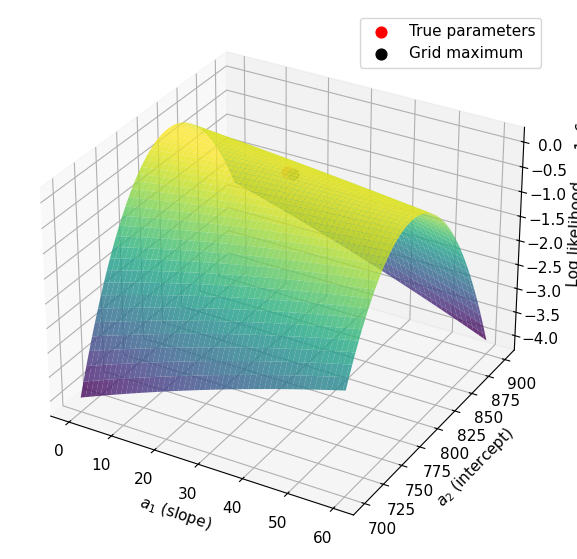

In [59]:
a1s = np.linspace(0, 60, 100)
a2s = np.linspace(700, 900, 100)
X, Y = np.meshgrid(a1s, a2s)

Z = np.empty_like(X)

for i in range(X.shape[0]):
    for j in range(X.shape[1]):
        Z[i, j] = log_likelihood((X[i, j], Y[i, j]), x, d, sigma)

# Find the maximum on this grid
i_max, j_max = np.unravel_index(np.argmax(Z), Z.shape)
a1_best = X[i_max, j_max]
a2_best = Y[i_max, j_max]

print(f"Grid maximum: a1 = {a1_best:.3f}, a2 = {a2_best:.3f}")

fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection="3d")

surface = ax.plot_surface(X, Y, Z, cmap="viridis", alpha=0.8)

ax.scatter(30, 800, log_likelihood((30, 800), x, d, sigma),
           color="red", s=60, label="True parameters"
           )
ax.scatter(a1_best, a2_best, Z[i_max, j_max], 
           color="black", s=60, label="Grid maximum"
           )

ax.set_xlabel(r"$a_1$ (slope)")
ax.set_ylabel(r"$a_2$ (intercept)")
ax.set_zlabel("Log likelihood")
ax.legend()
plt.show()


### Q2. Add a prior and obtain the posterior

Write the posterior probability for the parameters given the data.  Consider two priors:
- **Positive:** both parameters are nonnegative.
- **Interval:** $20\le a_1\le100$ and $300\le a_2\le3000$.

Write the log posterior using your likelihood. (return a constant inside the allowed region and $-\infty$ outside)

In [60]:
def log_prior(theta, prior="positive"):
    a1, a2 = theta
    if prior == "positive":
        allowed = (a1 >= 0) and (a2 >= 0)
    elif prior == "interval":
        allowed = (20 <= a1 <= 100) and (300 <= a2 <= 3000)
    else:
        raise ValueError("prior must be 'positive' or 'interval'")
    
    return 0.0 if allowed else -np.inf


def log_posterior(theta, x, d, sigma, prior="positive"):
    lp = log_prior(theta, prior)
    
    if not np.isfinite(lp):
        return -np.inf
    
    return log_likelihood(theta, x, d, sigma) + lp


### Q3(i). Implement a simple Metropolis sampler

At the current state $\theta$, propose

$$
\theta'=\theta+\eta,
\qquad \eta_j\sim\mathcal N(0, \sigma_j^2).
$$

The proposal is symmetric: proposing the reverse move has the same density. Therefore accept with probability

$$
A=\min\left(1,\frac{p(\theta'\mid d)}{p(\theta\mid d)}\right).
$$

Equivalently, draw $u$ uniformly on $(0,1)$ and accept when

$$
\log u<\min\{0,\log p(\theta'\mid d)-\log p(\theta\mid d)\}.
$$


Complete this algorithm. Store the current state after every step, including rejections. You can start with $\eta_1 = 1$ for the first parameter $a_1$ and $\eta_2 =10$ for $a_2$. Notice that these values are only a choice.


### Why Metropolis sampling satisfies detailed balance

Metropolis sampling constructs a **Markov chain in parameter space**. Each state is a parameter vector; in our example,

$$
\theta^{(t)}=(a_1^{(t)},a_2^{(t)}).
$$

The chain is Markov because the next state depends only on the current state and fresh randomness.

Let $p(\theta)$ denote the target posterior density. For two distinct states, the transition density is

$$
T(\theta'\mid\theta)
=
q(\theta'\mid\theta)\,A(\theta\to\theta'),
$$

where $q(\theta'\mid\theta)$ is the proposal density and $A(\theta\to\theta')$ is the acceptance probability.

**Detailed balance** requires

$$
p(\theta)T(\theta'\mid\theta)
=
p(\theta')T(\theta\mid\theta').
$$

At equilibrium, the probability flow between any two regions balances the reverse flow.

For a symmetric proposal,

$$
q(\theta'\mid\theta)=q(\theta\mid\theta'),
$$

the Metropolis acceptance rule is

$$
A(\theta\to\theta')
=
\min\left(1,\frac{p(\theta')}{p(\theta)}\right).
$$

Substituting this rule into the forward flow gives

$$
\begin{aligned}
p(\theta)T(\theta'\mid\theta)
&=
q(\theta'\mid\theta)\,
p(\theta)\min\left(1,\frac{p(\theta')}{p(\theta)}\right)\\
&=
q(\theta'\mid\theta)\min\bigl(p(\theta),p(\theta')\bigr).
\end{aligned}
$$

Similarly, the reverse flow is

$$
p(\theta')T(\theta\mid\theta')
=
q(\theta\mid\theta')\min\bigl(p(\theta'),p(\theta)\bigr).
$$

These expressions are equal because the proposal is symmetric. Therefore, **the Metropolis acceptance rule satisfies detailed balance**. Rejections contribute a probability of staying at the current state, which balances with itself.

### Intuition

Suppose

$$
p(\theta')=3p(\theta).
$$

- From $\theta$ to $\theta'$, every proposal is accepted.
- From $\theta'$ to $\theta$, a proposal is accepted with probability $1/3$.

At equilibrium, there is three times as much probability density at $\theta'$, but the acceptance probability for moving back toward $\theta$ is three times smaller. The probability flows therefore balance.

### Connection to posterior sampling

Detailed balance ensures that the posterior is a **stationary distribution**: if the chain follows the posterior, further Metropolis steps preserve that distribution.

Convergence from an arbitrary starting point also requires suitable exploration conditions, such as irreducibility and aperiodicity. Detailed balance alone does not guarantee convergence.

After convergence, the fraction of iterations spent in a region approximates its posterior probability. We must record the state after **every iteration**, including rejections, to preserve these occupancy frequencies.

In [61]:
def metropolis(log_prob, proposal_scales, initial, n_steps=10_000):
    chain = np.zeros((n_steps, len(initial)))
    current = initial
    chain[0, :] = initial
    
    log_probs = np.zeros(n_steps)
    log_probs[0] = log_prob(current)
    n_accepted = 0
    
    for i in range(n_steps):
        proposal = current + rng.normal(0, proposal_scales)
        log_prob_proposal = log_prob(proposal)
        log_ratio = log_prob_proposal - log_prob(current)
        
        if np.log(rng.uniform()) < min(0.0, log_ratio):
            current = proposal
            n_accepted += 1

        chain[i] = current
        log_probs[i] = log_prob_proposal
        
    acceptance_fraction = n_accepted / n_steps
    return chain, log_probs, acceptance_fraction

### Choosing the proposal size

First try the original proposal scales $(1,10)$ for a short run. Then use smaller scales $(0.1,0.05)$ for the main run.

Compare the acceptance fractions and movement of the chains. Explain why proposal scales should be related to the posterior's width rather than the parameter's absolute value.

Plot the log-probability as a function of Monte-Carlo Step. Compare to the log-likelihood with the true parameters.

Acceptance fraction: 0.004
Average [ 30.13352148 799.89066136]
Std [0.24825074 0.14202124]


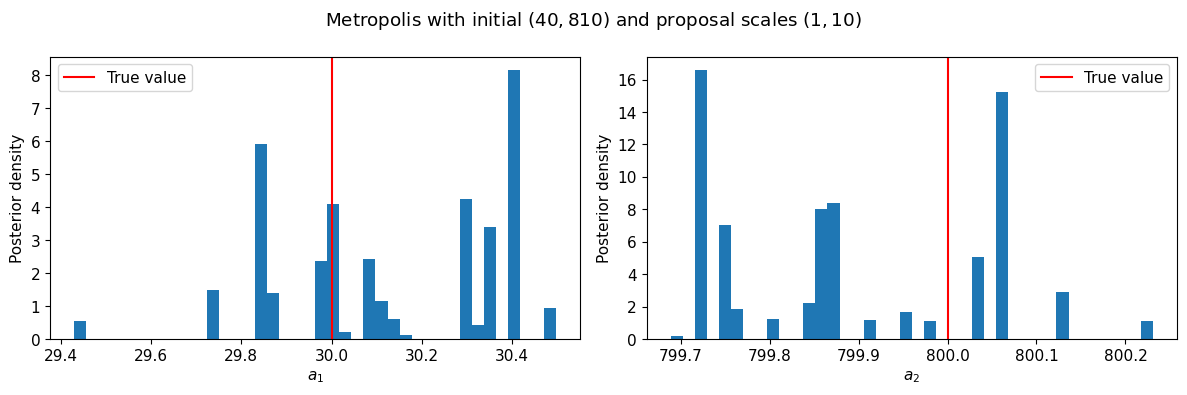

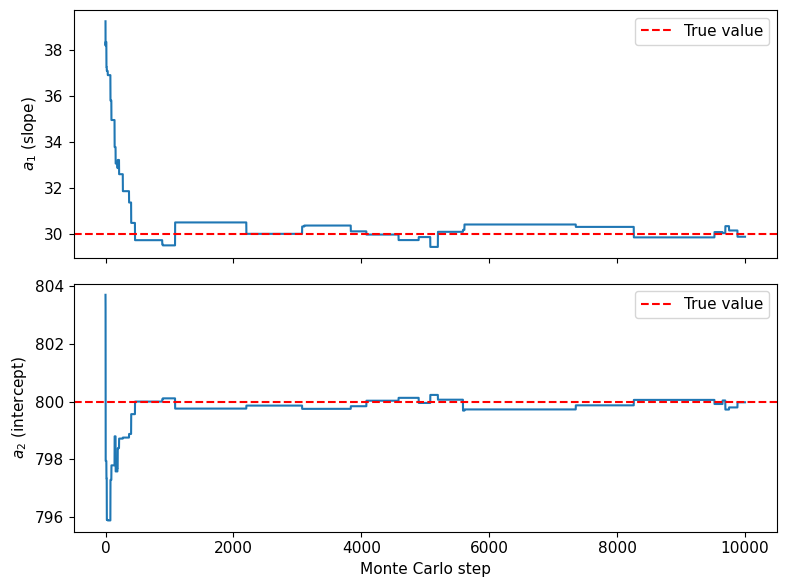

In [64]:
def target(theta):
    return log_posterior(theta, x, d, sigma)

initial = (40, 810)
proposal_scales = (1, 10)

chain, log_probs, acceptance = metropolis(
    log_prob=target,
    initial=initial,
    proposal_scales=proposal_scales,
    n_steps=10_000
)

print(f"Acceptance fraction: {acceptance:.3f}")

margin = 2000
samples = chain[margin:]

print("Average", np.mean(samples, axis=0))
print("Std", np.std(samples, axis=0))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(samples[:, 0], bins=40, density=True)
axes[0].axvline(30, color="red", label="True value")
axes[0].set(xlabel=r"$a_1$", ylabel="Posterior density")
axes[0].legend()

axes[1].hist(samples[:, 1], bins=40, density=True)
axes[1].axvline(800, color="red", label="True value")
axes[1].set(xlabel=r"$a_2$", ylabel="Posterior density")
axes[1].legend()

fig.suptitle(rf"Metropolis with initial ${initial}$ and proposal scales ${proposal_scales}$")

plt.tight_layout()


fig, axes = plt.subplots(2, 1, figsize=(8, 6), sharex=True)

axes[0].plot(chain[:, 0])
axes[0].axhline(a1_t, color="red", linestyle="--", label="True value")
axes[0].set_ylabel(r"$a_1$ (slope)")
axes[0].legend()

axes[1].plot(chain[:, 1])
axes[1].axhline(a2_t, color="red", linestyle="--", label="True value")
axes[1].set_ylabel(r"$a_2$ (intercept)")
axes[1].set_xlabel("Monte Carlo step")
axes[1].legend()

plt.tight_layout()


Acceptance fraction: 0.499
Average [ 30.03451796 799.94197347]
Std [0.15620722 0.08977775]


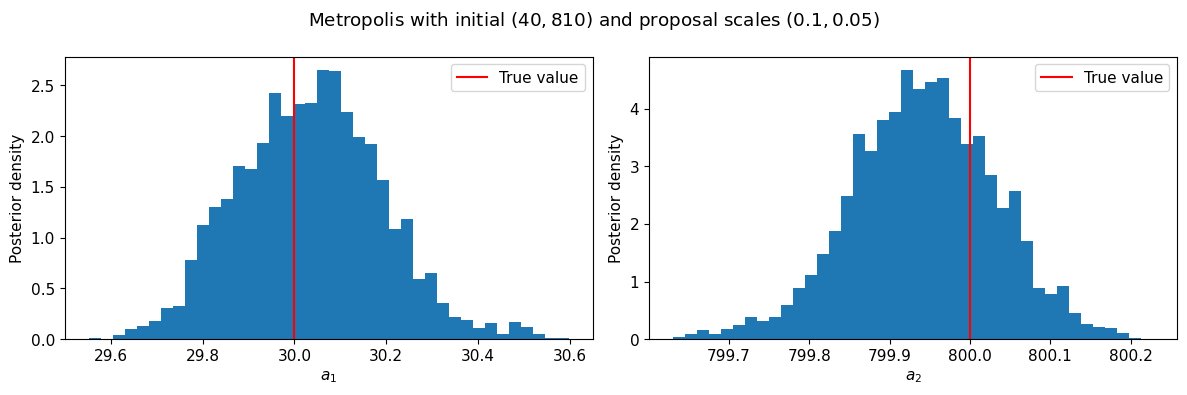

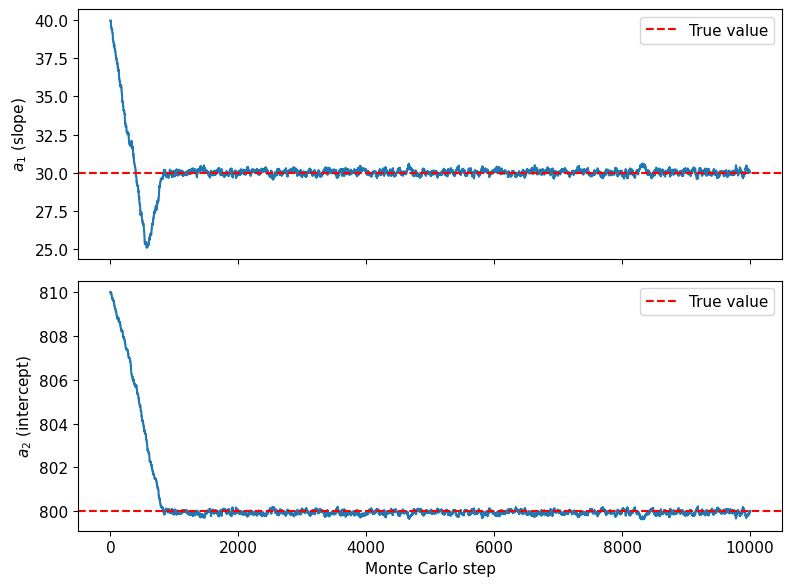

In [66]:

initial = (40, 810)
proposal_scales = (0.1, 0.05)

chain, log_probs, acceptance = metropolis(
    log_prob=target,
    initial=initial,
    proposal_scales=proposal_scales,
    n_steps=10_000
)

print(f"Acceptance fraction: {acceptance:.3f}")

margin = 2000
samples = chain[margin:]

print("Average", np.mean(samples, axis=0))
print("Std", np.std(samples, axis=0))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(samples[:, 0], bins=40, density=True)
axes[0].axvline(30, color="red", label="True value")
axes[0].set(xlabel=r"$a_1$", ylabel="Posterior density")
axes[0].legend()

axes[1].hist(samples[:, 1], bins=40, density=True)
axes[1].axvline(800, color="red", label="True value")
axes[1].set(xlabel=r"$a_2$", ylabel="Posterior density")
axes[1].legend()

fig.suptitle(rf"Metropolis with initial ${initial}$ and proposal scales ${proposal_scales}$")

plt.tight_layout()


fig, axes = plt.subplots(2, 1, figsize=(8, 6), sharex=True)

axes[0].plot(chain[:, 0])
axes[0].axhline(a1_t, color="red", linestyle="--", label="True value")
axes[0].set_ylabel(r"$a_1$ (slope)")
axes[0].legend()

axes[1].plot(chain[:, 1])
axes[1].axhline(a2_t, color="red", linestyle="--", label="True value")
axes[1].set_ylabel(r"$a_2$ (intercept)")
axes[1].set_xlabel("Monte Carlo step")
axes[1].legend()

plt.tight_layout()


### Q3(iii). Describe the posterior samples

Plot marginal histograms and the joint distribution with `corner`. Estimate the means and variances. Are the generating parameters in a plausible part of the distribution? Explain the slope–intercept correlation.



a_1: mean = 30.05252, variance = 0.364971, 95% credible interval = [29.69961, 30.38006]
a_2: mean = 800.05334, variance = 0.737154, 95% credible interval = [799.76351, 800.18242]
Slope-intercept correlation: -0.893


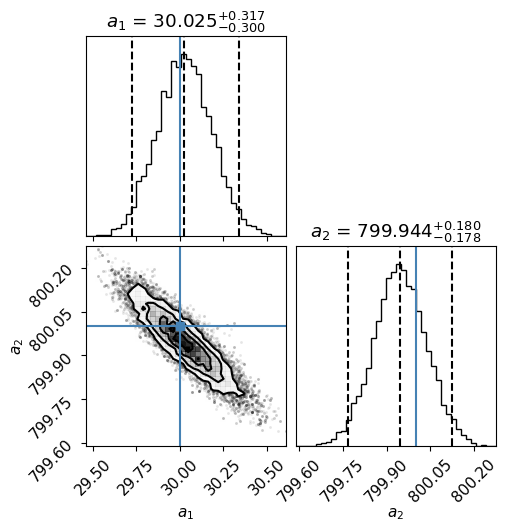

In [74]:
means = np.mean(chain, axis=0)
variances = np.var(chain, axis=0)
intervals = np.quantile(chain, [0.025, 0.975], axis=0)
correlation = np.corrcoef(samples.T)[0, 1]

for j, name in enumerate(["a_1", "a_2"]):
    print(
        f"{name}: mean = {means[j]:.5f}, "
        f"variance = {variances[j]:.6f}, "
        f"95% credible interval = "
        f"[{intervals[0, j]:.5f}, {intervals[1, j]:.5f}]"
    )
    
print(f"Slope-intercept correlation: {correlation:.3f}")

fig = corner.corner(
    samples,
    labels=[r"$a_1$", r"$a_2$"],
    truths=[30, 800],
    bins=40,
    quantiles=[0.025, 0.5, 0.975],
    show_titles=True,
    title_fmt=".3f"
)
plt.show()

### Q4. Compare the two priors

Rerun the sampler with the interval prior, a different starting point and a different seed. Compare its traces and parameter distributions with the first run.



Interval-prior acceptance: 49.740%

Positive prior
Means: [ 30.02648876 799.94501907]
Variances: [0.02471606 0.00821749]

Interval prior
Means: [ 30.03346355 799.94075038]
Variances: [0.02458979 0.00816156]


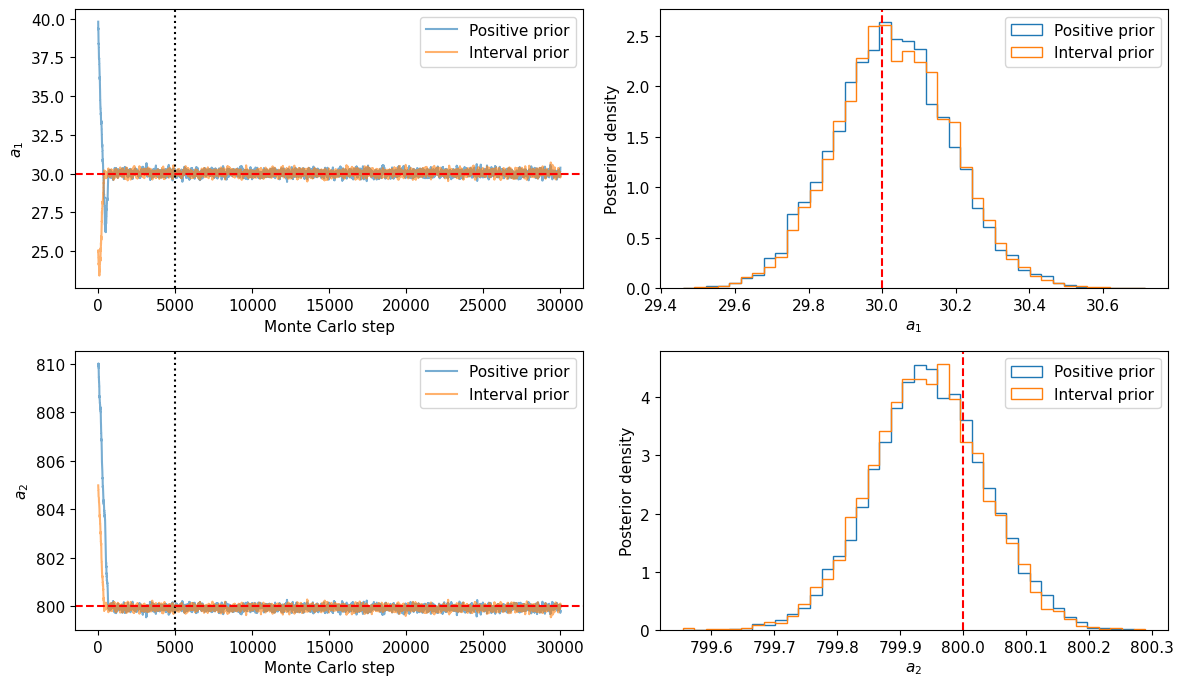

In [76]:
def target_interval(theta):
    return log_posterior(theta, x, d, sigma, prior="interval")


chain_interval, logs_interval, acc_interval = metropolis(
    log_prob=target_interval,
    initial=[25, 805],
    proposal_scales=[0.1, 0.05],
    n_steps=30_000
    )

samples_interval = chain_interval[burn_in:]

print(f"Interval-prior acceptance: {acc_interval:.3%}")

for name, retained in [
    ("Positive prior", samples),
    ("Interval prior", samples_interval)
]:
    print(f"\n{name}")
    print("Means:", np.mean(retained, axis=0))
    print("Variances:", np.var(retained, axis=0, ddof=1))

fig, axes = plt.subplots(2, 2, figsize=(12, 7))

for j, label in enumerate([r"$a_1$", r"$a_2$"]):
    axes[j, 0].plot(chain[:, j], alpha=0.6, label="Positive prior")
    axes[j, 0].plot(chain_interval[:, j], alpha=0.6,
                    label="Interval prior")
    axes[j, 0].axvline(burn_in, color="black", ls=":")
    axes[j, 0].axhline([30, 800][j], color="red", ls="--")
    axes[j, 0].set(xlabel="Monte Carlo step", ylabel=label)

    # Common bin edges make the two histograms directly comparable.
    bins = np.histogram_bin_edges(
        np.concatenate([samples[:, j], samples_interval[:, j]]),
        bins=40
    )

    axes[j, 1].hist(samples[:, j], bins=bins, density=True,
                    histtype="step", label="Positive prior")
    axes[j, 1].hist(samples_interval[:, j], bins=bins, density=True,
                    histtype="step", label="Interval prior")
    axes[j, 1].axvline([30, 800][j], color="red", ls="--")
    axes[j, 1].set(xlabel=label, ylabel="Posterior density")

for ax in axes.flat:
    ax.legend()

plt.tight_layout()

The two posterior distributions are similar because the likelihood is concentrated well inside both priors' allowed regions. The interval prior excludes regions with negligible likelihood, so it provides little additional constraint beyond the data. Any small differences between the sampled distributions may arise from finite sampling and chain convergence.

### End of Session 1

Explain why noisy observations carry less weight and why Metropolis sometimes accepts lower-density proposals.

## Part 2 — Apply the same statistical method to GW150914

Gravitational waves are traveling perturbations in space-time, generated by cataclysmic events
in distant galaxies. The detection of gravitational waves has been a long-held goal of the physics community, and represents a further confirmation of Einstein’s Theory of General Relativity. On September 14, 2015, the two detectors of the Laser Interferometer Gravitational-wave Observatory (LIGO) observed a gravitational wave signal (GW150914) generated by the merger of two black holes. The LIGO detectors had been recently upgraded with new instrumentation and operating as Advanced LIGO, able to measure changes in the local shape of space-time with a precision better than one-thousandth the diameter of a proton. This discovery was
awarded by a nobel prize in 2017.

The L-shaped LIGO instruments consist of two perpendicular arms, each two of 4 kilometers long. A passing gravitational wave will alternately stretch one arm and squeeze the other, and then vice-versa; this generates an interference pattern at the readout port of the interferometer, which is measured by photo-detectors (Fig.1). Nice divulgation tutorials can be viewed in https://www.gw-openscience.org/path/.
The goal of this tutorial is to use Metropolis Sampling and Bayes Inference to measure the parameters of the binary black holes collision event detected by the gravitational wave GW150914, focusing on the inference of their masses and their lumonisity distance.
<!-- Eric Chassande-Mottin (laboratoire AstroParticule et Cosmologie (APC) Paris ) has kindly provided us the access to the data and to the signal pre-treatement.  -->



GW150914 was recorded by the Hanford (H1) and Livingston (L1) detectors. Each detector supplies a time series of strain, a dimensionless measure of deformation. We will use H1 for parameter inference and L1 for a visual comparison.

Our two model parameters are $\theta=(m,D)$: an assumed common component mass $m_1=m_2=m$ and a distance-like amplitude scale $D$. Masses are in solar masses and $D$ is in megaparsecs (Mpc).


The goal of this section is to follow previous steps implemented for artificial data and find distribution of the parameters $\theta$, their average values and variance, including the corner plots of distribution of parameters during the MC sampling.

![](Exp.png)

**Figure 1:**
Sketch and description of the experiment from [5]. As laser light bounces back and forth along
arms between its mirrors, LIGO senses gravitational waves as minuscule fluctuations in the lengths of the.


### Q5. Read the supplied inputs and inspect the data

| Supplied object | Meaning |
|---|---|
| `strain_H1`, `strain_L1` | Prepared detector time series |
| `d_gw` | Complex Fourier coefficients of an 8 s H1 interval |
| `psd_gw` | Noise power spectrum on the same frequency grid |
| `frequency`, `delta_f` | Frequencies and spacing between frequency bins |
| `gen_template(theta)` | Predicted complex Fourier coefficients for $(m,D)$ |

The preparation removes very low frequencies, downsamples the data and estimates the noise spectrum from intervals outside the event. 

The noise PSD $S(f)$ has units $\text{strain}^2/\text{Hz}$; its square root is the amplitude spectral density (ASD). A high PSD means that observations around that frequency are noisy. This replaces the known, observation-dependent noise variances in Part 1.

Inspect both time series and noise spectra. Why should two detectors have different noise weights? Why is it useful to estimate the noise outside the event?

In [ ]:
# PROVIDED: prepare the two detectors and the Fourier inputs for inference.
import warnings
warnings.filterwarnings("ignore", message="Wswiglal-redir-stdio.*")
from scipy.signal import welch, windows
from pycbc.types import TimeSeries, FrequencySeries
from pycbc.filter import highpass, resample_to_delta_t
from pycbc.waveform import get_fd_waveform
import lal

EVENT_TIME, FS = 1126259462.4, 2048

def prepare_detector(name):
    with np.load(Path(f"GW150914_{name}_raw.npz"), allow_pickle=False) as saved:
        raw = TimeSeries(saved["strain"], delta_t=float(saved["delta_t"]),
                         epoch=float(saved["epoch"]))
    strain = resample_to_delta_t(highpass(raw, 15), 1 / FS).crop(2, 2)
    noise_estimates = []
    for start, end in [(EVENT_TIME - 10, EVENT_TIME - 2), (EVENT_TIME + 2, EVENT_TIME + 10)]:
        f_noise, noise = welch(np.asarray(strain.time_slice(start, end)), fs=FS,
                              nperseg=4 * FS, noverlap=2 * FS, average="median")
        noise_estimates.append(noise)
    return strain, f_noise, np.mean(noise_estimates, axis=0)

strain_H1, f_noise, noise_H1 = prepare_detector("H1")
strain_L1, _, noise_L1 = prepare_detector("L1")
fit_strain = strain_H1.time_slice(EVENT_TIME - 4, EVENT_TIME + 4)
fit_strain = TimeSeries(np.asarray(fit_strain) * windows.tukey(len(fit_strain), 0.1),
                        delta_t=fit_strain.delta_t, epoch=fit_strain.start_time)
data_frequency = fit_strain.to_frequencyseries()
d_gw = np.asarray(data_frequency)
frequency = np.asarray(data_frequency.sample_frequencies)
delta_f = float(data_frequency.delta_f)
psd_gw = np.interp(frequency, f_noise, noise_H1)
band = (frequency >= 20) & (frequency < 512)
print(f"Prepared H1 and L1: {FS} Hz; H1 fit interval {fit_strain.duration:.0f} s.")

PyCBC.libutils: pkg-config call failed, setting NO_PKGCONFIG=1


Prepared H1 and L1: 2048 Hz; H1 fit interval 8 s.


![Fig3.png](Fig3.png)

**Figure 2:** Amplitude spectral density of the total strain noise of the Virgo (violet), Ligo-Hanford LHO (red),
and Ligo-Livingston LLO (blue) detectors. The curves are representative of the best performance of each
detector during O2.[4]. Peaks correspond to known noises sources such as seismic (from ground vibrations),
thermal noise (from the microscopic fluctuations of the individual atoms in the mirrors), quantum noise (from
photon counting in the photodetector),laser noises ( small variations in the laser intensity and frequency),
beam jitter (misalign the laser beam with respect to the optical cavities),Scattered light, generated by tiny
imperfections in the mirrors of the interferometers, etc.. [4].

#### The supplied model function

The model, given by $\mu_k(\theta)$, describes the fourrier coefficients  based on Einstein's general relativity theory and the metric perturbation due to a collision event [1].
This model is already implemented by the function `gen_template([m, D])` provided from the pycbc package. It returns the model prediction on the data's frequency grid.


In [ ]:
# PROVIDED: a physical forward model, used as a callable function.
# Time and phase are fixed teaching settings, calibrated on H1.
fixed_time = 1126259462.4280396
fixed_phase = 2.9727073389131307
alignment = np.exp(-2j * np.pi * frequency * (fixed_time - float(fit_strain.start_time))
                   + 1j * fixed_phase)

def gen_template(theta):
    m, D = theta
    with lal.no_swig_redirect_standard_output_error():
        hp, _ = get_fd_waveform(approximant="IMRPhenomD", mass1=float(m), mass2=float(m),
                                spin1z=0, spin2z=0, inclination=0, distance=float(D),
                                coa_phase=0, f_ref=100, delta_f=delta_f,
                                f_lower=20, f_final=FS / 2)
    hp.resize(len(d_gw))
    return np.asarray(hp) * alignment

### Q6. Write the real-data likelihood and posterior

The relevant log likelihood is

$$
\log\mathcal L(d\mid\theta)
=-2\Delta f\sum_{k\in\mathcal B}
\frac{|d_k-\mu_k(\theta)|^2}{S(f_k)}+\text{constant}.
$$

Here $\mu(\theta)$ is the supplied template, $\Delta f$ is the frequency spacing, and $\mathcal B$ contains frequencies from 20 to below 512 Hz. The data and model use the same FFT normalization. The factor $2 \Delta f$ comes from a factor of $1/2$ in the normal
distribution and a factor of $4\Delta f$ needed to convert the square of the Fourier transforms into units of one-
sided (having only positive frequencies) power spectral density. 


Compare this expression with Q1. Implement it using `gen_template`, `d_gw`, `psd_gw` and `band`. Why must you use $|r|^2$ rather than $r^2$ for a complex residual?

Consider two uniform priors:

| Prior | $m$ [$M_\odot$] | $D$ [Mpc] |
|---|---|---|
| Broad | $[20,100]$ | $[100,4000]$ |
| Interval | $[20,100]$ | $[300,3000]$ |

Notice that unlike the regression example, a positive-only distance restriction is insufficient. The waveform tends to zero at infinite distance, leaving a nonzero likelihood tail that cannot be normalized with an unbounded constant prior.


### Q7. Reuse Metropolis on the real data

Reuse your existing sampler. Plot parameter traces and the log posterior, discard an initial transient, and summarize the retained distributions. Repeat with the broad prior, another starting point and another seed. Compare the runs.

Proposed scales: $(0.25\ M_\odot,40\ \mathrm{Mpc})$

### Q8. Compare the model with the measured signal

Whitening gives less weight to noisy frequencies and makes the event easier to see. The helper below also keeps only 30–300 Hz for this display. Use the same processing for data and template.

Plot a representative template from the retained samples against H1. Then compare H1 and L1. Does a similar pattern appear? What does the time shift mean?

The detector delay calculation is supplied. It chooses the strongest absolute correlation within 10 ms and records whether the patterns have the same or opposite sign. It measures a delay from the data.

In [ ]:
# PROVIDED: make a band-limited whitened time series for display.
def whiten_for_plot(strain, noise):
    f = np.fft.rfftfreq(len(strain), d=float(strain.delta_t))
    psd = np.interp(f, f_noise, noise)
    keep = (f >= 30) & (f <= 300)
    spectrum = np.zeros(len(f), dtype=complex)
    spectrum[keep] = np.fft.rfft(np.asarray(strain))[keep] / np.sqrt(psd[keep] * FS / 2)
    return TimeSeries(np.fft.irfft(spectrum, n=len(strain)),
                       delta_t=strain.delta_t, epoch=strain.start_time)

white_H1 = whiten_for_plot(strain_H1, noise_H1)
white_L1 = whiten_for_plot(strain_L1, noise_L1)
theta_fit = np.median(samples_gw, axis=0)
template = FrequencySeries(gen_template(theta_fit), delta_f=delta_f,
                           epoch=fit_strain.start_time).to_timeseries()
white_template = whiten_for_plot(template, noise_H1)

from scipy.signal import correlate, correlation_lags
H = white_H1.time_slice(EVENT_TIME - 0.15, EVENT_TIME + 0.05)
L = white_L1.time_slice(EVENT_TIME - 0.15, EVENT_TIME + 0.05)
correlation = correlate(np.asarray(H), np.asarray(L), mode="full")
lags = correlation_lags(len(H), len(L), mode="full") / FS
allowed = np.flatnonzero(np.abs(lags) <= 0.010)
peak = allowed[np.argmax(np.abs(correlation[allowed]))]
delay = float(lags[peak])
relative_sign = float(np.sign(correlation[peak]))


# References:

[[1](https://arxiv.org/abs/1809.02293)] Eric Thrane and Colm Talbot An introduction to Bayesian inference in gravitational-wave astron-
omy: parameter estimation, model selection, and hierarchical models Astronomical Society of Australia
(PASA) doi: 10.1017/pas.2020.xxx. (2020)

[[2](https://arxiv.org/abs/gr-qc/0008066)] Anderson W. G., Brady P. R., Creighton J. D. E., Flana- gan E. E., 2001, Phys. Rev. D, 63, 042003

[3] Codes available at [bilby example](https://bilby-dev.github.io/bilby/examples.html) and [gw-odw](https://github.com/gw-odw/odw-2018/tree/master/gwpy).

[[4](https://arxiv.org/abs/1811.12907)] B. P. Abbott et al. GWTC-1: A Gravitational-Wave Transient Catalog of Compact Binary Mergers
Observed by LIGO and Virgo during the First and Second Observing Runs. arXiv. This should lead
to discussion and interpretation. The data used in these tutorials will be downloaded from the public
DCC page LIGO-P1800370. Phys.Review X 9, 031040 (2019)

[5] see [ligo.org](https://www.ligo.org/science/Publication-O1Noise/index.php) and [Nobel prize](https://cen.acs.org/articles/95/web/2017/10/Detection-of-gravitational-waves-wins-2017-Nobel-Prize-in-Physics.html) description for a brief description of the experiment.